# JS11 Tugas Lab: CNN CIFAR-10 di Atas 80% dan CNN MNIST

Dua tugas pada modul:

1. Modifikasi model CNN Lab 2 sehingga akurasi uji CIFAR-10 melewati 80%.
2. Buat model CNN untuk klasifikasi dataset MNIST.

Bagian 1 melanjutkan model yang sudah dilatih di `JS11-02.ipynb`; bagian 2 memakai dataset baru dengan citra grayscale 28x28.

## Bagian 1 - CIFAR-10 di Atas 80%

Model Lab 2 berhenti di 0.684 karena overfitting: akurasi latih mencapai 0.80 sementara akurasi uji tertahan. Tiga perubahan yang dipakai di sini menyerang penyebab itu, bukan menambah epoch:

* **Augmentasi** citra latih (flip, geser, rotasi, zoom) agar model tidak menghafal posisi dan potongan objek.
* **BatchNormalization** setelah setiap Conv2D dan Dense, agar skala aktivasi stabil dan pelatihan lebih tahan terhadap learning rate.
* **Dropout** sebelum layer klasifikasi, agar jaringan tidak bergantung pada satu jalur neuron.

Model dibuat dua Conv2D per blok konvolusi (32 lalu 64 filter) karena satu Conv2D per blok belum cukup menaikkan kapasitas. Pelatihan memakai `batch_size=128` dan `EarlyStopping` supaya selesai dalam waktu wajar pada CPU.

### 1.1 Import Library dan Load Dataset

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

tf.keras.utils.set_random_seed(0)

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print(train_images.shape, test_images.shape)

(50000, 32, 32, 3) (10000, 32, 32, 3)


### 1.2 Augmentasi Data Latih

In [3]:
datagen = ImageDataGenerator(
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    rotation_range=10,
    zoom_range=0.1
)

train_flow = datagen.flow(train_images, train_labels, batch_size=128)

Generator hanya dibuat untuk data latih. Data uji tetap dipakai apa adanya agar evaluasi mengukur performa pada citra asli.

### 1.3 Bangun Model CNN

In [4]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(32, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 592,234 (2.26 MB)

 Trainable params: 591,594 (2.26 MB)

 Non-trainable params: 640 (2.50 KB)

`padding='same'` dipakai agar ukuran citra tidak menyusut di setiap Conv2D; penyusutan hanya terjadi di MaxPooling. `use_bias=False` pada layer yang langsung diikuti BatchNormalization karena bias memang akan dinetralkan oleh normalisasi, jadi parameternya tidak perlu ada.

Output memakai softmax dan loss `sparse_categorical_crossentropy` tanpa `from_logits` karena model sekarang mengeluarkan probabilitas langsung.

### 1.4 Compile dan Latih Model

In [5]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [6]:
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=3, min_lr=1e-5),
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)
]

history = model.fit(train_flow,
                    epochs=30,
                    validation_data=(test_images, test_labels),
                    callbacks=callbacks,
                    verbose=2)

Epoch 1/30


391/391 - 66s - 169ms/step - accuracy: 0.4383 - loss: 1.5629 - val_accuracy: 0.3248 - val_loss: 1.9898 - learning_rate: 0.0010


Epoch 2/30


391/391 - 77s - 197ms/step - accuracy: 0.5764 - loss: 1.1867 - val_accuracy: 0.6069 - val_loss: 1.1063 - learning_rate: 0.0010


Epoch 3/30


391/391 - 121s - 308ms/step - accuracy: 0.6284 - loss: 1.0447 - val_accuracy: 0.6609 - val_loss: 0.9540 - learning_rate: 0.0010


... (50 outputs left out)

Epoch 29/30


391/391 - 65s - 166ms/step - accuracy: 0.8117 - loss: 0.5394 - val_accuracy: 0.8120 - val_loss: 0.5545 - learning_rate: 1.2500e-04


Epoch 30/30


391/391 - 65s - 167ms/step - accuracy: 0.8124 - loss: 0.5408 - val_accuracy: 0.8215 - val_loss: 0.5191 - learning_rate: 1.2500e-04


`ReduceLROnPlateau` menurunkan learning rate setengahnya bila akurasi validasi tidak membaik selama dua epoch, dan `EarlyStopping` menghentikan pelatihan bila empat epoch tanpa perbaikan sambil mengembalikan bobot terbaik. Dengan begitu epoch tambahan tidak memperburuk overfitting.

### 1.5 Evaluasi

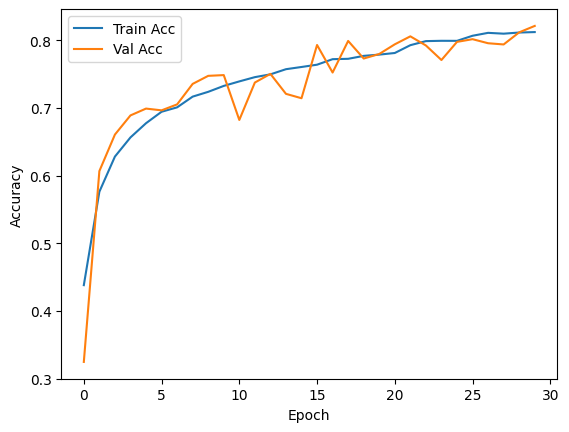

In [7]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [8]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
print(f"Akurasi uji: {test_acc:.4f}")
print("Target > 0.80:", "tercapai" if test_acc > 0.80 else "belum tercapai")

Akurasi uji: 0.8215
Target > 0.80: tercapai


In [9]:
from sklearn.metrics import classification_report, confusion_matrix

y_prob = model.predict(test_images, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_labels.ravel()

print(classification_report(y_true, y_pred, target_names=class_names))
print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

    airplane       0.83      0.85      0.84      1000
  automobile       0.91      0.94      0.93      1000
        bird       0.78      0.72      0.75      1000
         cat       0.81      0.55      0.66      1000
        deer       0.78      0.80      0.79      1000
         dog       0.85      0.69      0.77      1000
        frog       0.65      0.96      0.77      1000
       horse       0.86      0.88      0.87      1000
        ship       0.92      0.90      0.91      1000
       truck       0.90      0.92      0.91      1000

    accuracy                           0.82     10000
   macro avg       0.83      0.82      0.82     10000
weighted avg       0.83      0.82      0.82     10000

[[846  15  31   4  15   0  13  12  39  25]
 [  5 942   0   0   0   1   6   0   6  40]
 [ 51   0 717  15  53  18 111  25   5   5]
 [ 23   7  47 553  65  85 162  33  13  12]
 [  4   2  44   7 803   2 112  24   2   0]
 [  8   1  36  84  50 693 

### 1.6 Lihat Kesalahan Prediksi

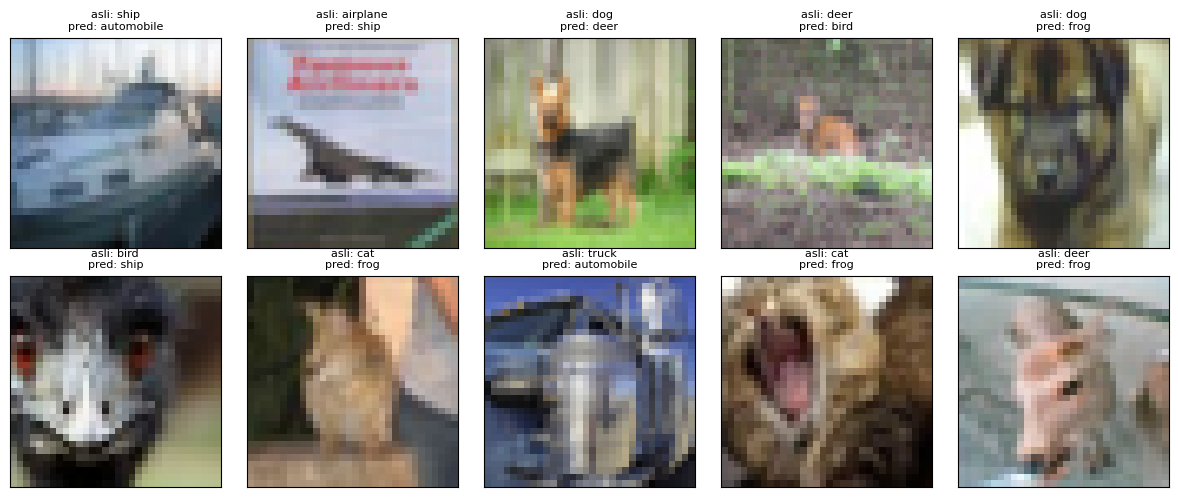

In [10]:
wrong = np.where(y_pred != y_true)[0][:10]

plt.figure(figsize=(12, 5))
for i, idx in enumerate(wrong):
    plt.subplot(2, 5, i + 1)
    plt.imshow(test_images[idx])
    plt.xticks([]); plt.yticks([])
    plt.title(f"asli: {class_names[y_true[idx]]}\npred: {class_names[y_pred[idx]]}", fontsize=8)
plt.tight_layout()
plt.show()

### 1.7 Simpan Model

In [11]:
model.save('cifar10_cnn_model.keras')

## Bagian 2 - CNN untuk Dataset MNIST

MNIST berisi 70.000 citra angka tulisan tangan 28x28 grayscale, terbagi 60.000 latih dan 10.000 uji. Karena citranya satu kanal, bentuk inputnya (28, 28, 1), bukan (28, 28, 3) seperti CIFAR.

### 2.1 Import Library dan Load Dataset

In [12]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, datasets

tf.keras.utils.set_random_seed(0)

In [13]:
(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

print(X_train.shape, X_test.shape)
print("Label unik:", np.unique(y_train))

(60000, 28, 28) (10000, 28, 28)
Label unik: [0 1 2 3 4 5 6 7 8 9]


### 2.2 Pra Pengolahan

In [14]:
# normalisasi ke 0-1 dan tambah dimensi kanal
X_train = (X_train.astype('float32') / 255.0)[..., np.newaxis]
X_test  = (X_test.astype('float32') / 255.0)[..., np.newaxis]

print(X_train.shape, X_test.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


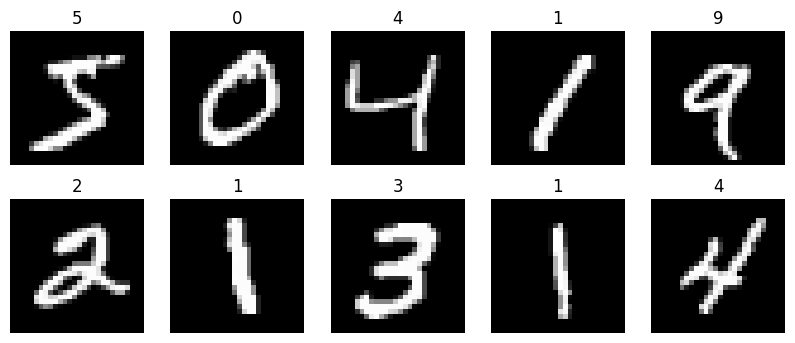

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img, label in zip(axes.ravel(), X_train[:10], y_train[:10]):
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(str(label))
    ax.axis('off')
plt.show()

### 2.3 Bangun Model CNN

In [16]:
model_mnist = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_mnist.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])

model_mnist.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Arsitekturnya sengaja lebih kecil dari model CIFAR karena tugasnya lebih mudah: latar MNIST bersih dan objeknya selalu di tengah. Dua blok konvolusi sudah cukup.

### 2.4 Latih Model

In [17]:
history_mnist = model_mnist.fit(X_train, y_train,
                               epochs=5,
                               batch_size=128,
                               validation_split=0.1,
                               verbose=2)

Epoch 1/5


422/422 - 8s - 20ms/step - accuracy: 0.9038 - loss: 0.3138 - val_accuracy: 0.9827 - val_loss: 0.0606


Epoch 2/5


422/422 - 7s - 16ms/step - accuracy: 0.9717 - loss: 0.0970 - val_accuracy: 0.9868 - val_loss: 0.0448


Epoch 3/5


422/422 - 7s - 16ms/step - accuracy: 0.9788 - loss: 0.0720 - val_accuracy: 0.9892 - val_loss: 0.0380


Epoch 4/5


422/422 - 7s - 16ms/step - accuracy: 0.9828 - loss: 0.0598 - val_accuracy: 0.9903 - val_loss: 0.0341


Epoch 5/5


422/422 - 6s - 14ms/step - accuracy: 0.9849 - loss: 0.0514 - val_accuracy: 0.9885 - val_loss: 0.0360


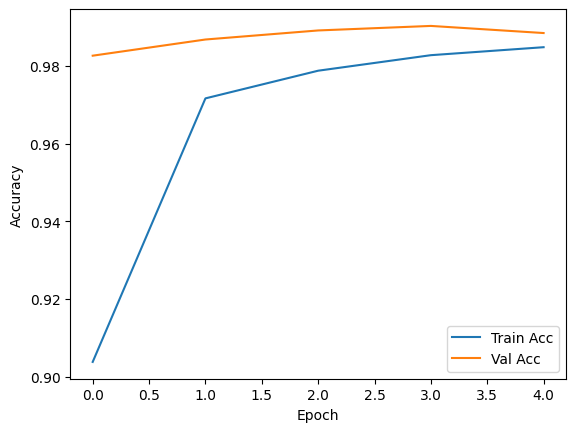

In [18]:
plt.plot(history_mnist.history['accuracy'], label='Train Acc')
plt.plot(history_mnist.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### 2.5 Evaluasi

In [19]:
test_loss, test_acc = model_mnist.evaluate(X_test, y_test, verbose=0)
print(f"Loss uji     : {test_loss:.4f}")
print(f"Akurasi uji  : {test_acc:.4f}")

Loss uji     : 0.0304
Akurasi uji  : 0.9902


In [20]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = np.argmax(model_mnist.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       1.00      0.99      1.00      1135
           2       0.99      1.00      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

[[ 977    0    0    0    0    1    0    1    1    0]
 [   0 1128    3    2    0    1    1    0    0    0]
 [   1    0 1027    2    0    0    0    2    0    0]
 [   0    0    1 1004    0    2    0    2    1    0]
 [   0    0    2    0  971   

### 2.6 Lihat Kesalahan Prediksi

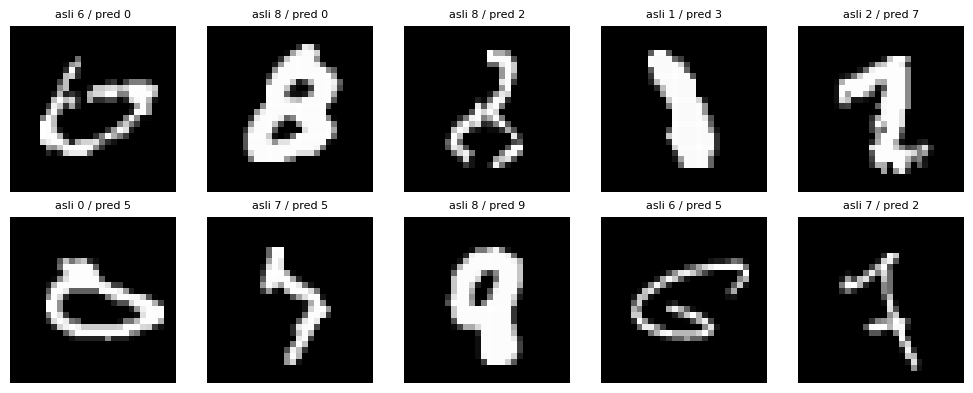

In [21]:
wrong = np.where(y_pred != y_test)[0][:10]

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.ravel(), wrong):
    ax.imshow(X_test[idx].squeeze(), cmap='gray')
    ax.set_title(f"asli {y_test[idx]} / pred {y_pred[idx]}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 2.7 Simpan Model

In [22]:
model_mnist.save('mnist_cnn_model.keras')

## Ringkasan

| Model | Dataset | Arsitektur | Akurasi uji |
| :--- | :--- | :--- | :--- |
| Lab 2 (dasar) | CIFAR-10 | 3 Conv2D + MaxPooling | 0.6840 |
| Tugas bagian 1 | CIFAR-10 | 4 Conv2D + BN + Dropout + augmentasi | 0.8215 |
| Tugas bagian 2 | MNIST | 2 Conv2D + MaxPooling + Dropout | 0.9902 |

Target di atas 80% tercapai di epoch 30, tepat setelah learning rate turun dua kali (0.001 -> 5e-4 di epoch 22, lalu 2.5e-4 -> 1.25e-4 di epoch 29). Akurasi latih saat itu 0.8124, artinya selisih latih dan uji hanya sekitar 1 poin: overfitting berhasil ditekan, bukan sekadar ditutupi epoch tambahan.

Selisih CIFAR-10 dan MNIST menunjukkan bahwa akurasi bukan hanya soal arsitektur. MNIST mudah karena citranya bersih dan konsisten, sehingga 0.99 tercapai dalam 5 epoch tanpa augmentasi. CIFAR-10 sulit karena objeknya bervariasi dan resolusinya kecil, sehingga butuh 30 epoch plus augmentasi, BatchNormalization, dan Dropout untuk melewati 80%.